In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [26]:
df = pd.read_csv('../data/processed/board_games_clean.csv')

In [27]:
df.head()

,BGGId,Name,YearPublished,ComWeight,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,NumOwned,NumWish,...,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens,Rating,perc_distance_playtime,belong_to_family
0,140386,Assassin's Creed: Arena,2014,2.0512,2,4,8,5.365976,6.270988,4.174387,...,0,0,0,0,0,0,0,1,0.000000,0
1,344114,Bag of Chips,2021,1.2256,2,5,8,3.610918,4.290459,3.871201,...,0,0,0,0,0,0,0,2,9.349442,0
2,319196,Gùgōng: Deluxe Big Box,2020,3.8190,1,5,10,1.000000,6.727432,4.158883,...,0,0,0,0,0,0,0,3,37.468764,0
3,11404,LetterFlip,2004,1.4216,2,2,7,1.000000,5.043425,2.079442,...,0,0,0,0,0,0,0,1,0.000000,0
4,281020,Treasures of Cibola,2019,1.6230,2,4,10,2.079442,5.342334,3.583519,...,0,0,0,0,0,0,0,2,9.349442,0


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20773 entries, 0 to 20772
Data columns (total 38 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BGGId                   20773 non-null  int64  
 1   Name                    20773 non-null  object 
 2   YearPublished           20773 non-null  int64  
 3   ComWeight               20773 non-null  float64
 4   MinPlayers              20773 non-null  int64  
 5   MaxPlayers              20773 non-null  int64  
 6   ComAgeRec               20773 non-null  int64  
 7   LanguageEase            20773 non-null  float64
 8   NumOwned                20773 non-null  float64
 9   NumWish                 20773 non-null  float64
 10  NumWeightVotes          20773 non-null  float64
 11  ComMinPlaytime          20773 non-null  float64
 12  ComMaxPlaytime          20773 non-null  float64
 13  MfgAgeRec               20773 non-null  int64  
 14  NumAlternates           20773 non-null

In [29]:
# 1. Creiamo la trasformazione
#df['MaxPlayers_c'] = df['MaxPlayers'].clip(upper=12)
features = [
    'YearPublished', 
    'ComWeight', 
    'MinPlayers', 
    'MaxPlayers', 
    'ComAgeRec', 
    'MfgAgeRec',
    'NumOwned',
    'NumWish',
    'NumWeightVotes',
    'ComMaxPlaytime',
    'ComMinPlaytime'
]
df_train = df[features]

In [30]:
scaler = MinMaxScaler()
X = scaler.fit_transform(df_train)

In [34]:
# elbow method and silhouette score
inertia = []
silhouette_scores = []

K = range(2, 52)
for k in K:
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=50, random_state=42)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)
    labels = kmeans.labels_
    silhouette_scores.append(silhouette_score(X, labels))
#print results
print("Inertia:", inertia)
print("Silhouette Scores:", silhouette_scores)


Inertia: [3626.5147766019604, 3117.194798815122, 2839.138085848282, 2588.3106044079495, 2408.318797773695, 2265.071654103039, 2144.012932614944, 2050.4951537569577, 1950.7804044958182, 1879.6180040487961, 1819.5490903431537, 1759.703511880276, 1713.026182713612, 1667.3841817362481, 1629.1530415473403, 1599.2308811703538, 1565.4063943005667, 1535.4915191561095, 1513.1325477508242, 1490.679872865746, 1466.4819333558016, 1443.4368703307646, 1424.8630904969068, 1405.2336870571062, 1390.860696820466, 1374.0126828446066, 1357.810488840933, 1343.2109207024193, 1328.8013459432525, 1316.8586367021426, 1302.128281559395, 1292.3444128145472, 1280.2688742188002, 1273.5992268758084, 1259.314728812089, 1248.8100918221628, 1238.8208470702061, 1230.2962177073878, 1219.8702248494387, 1210.3771518655658, 1201.8048918589604, 1194.1770714673103, 1185.4193352041698, 1176.5928438879587, 1169.9430046544105, 1166.1161518202332, 1155.5116738629229, 1149.6490202752525, 1142.138253369011, 1134.9061556667357]
Sil

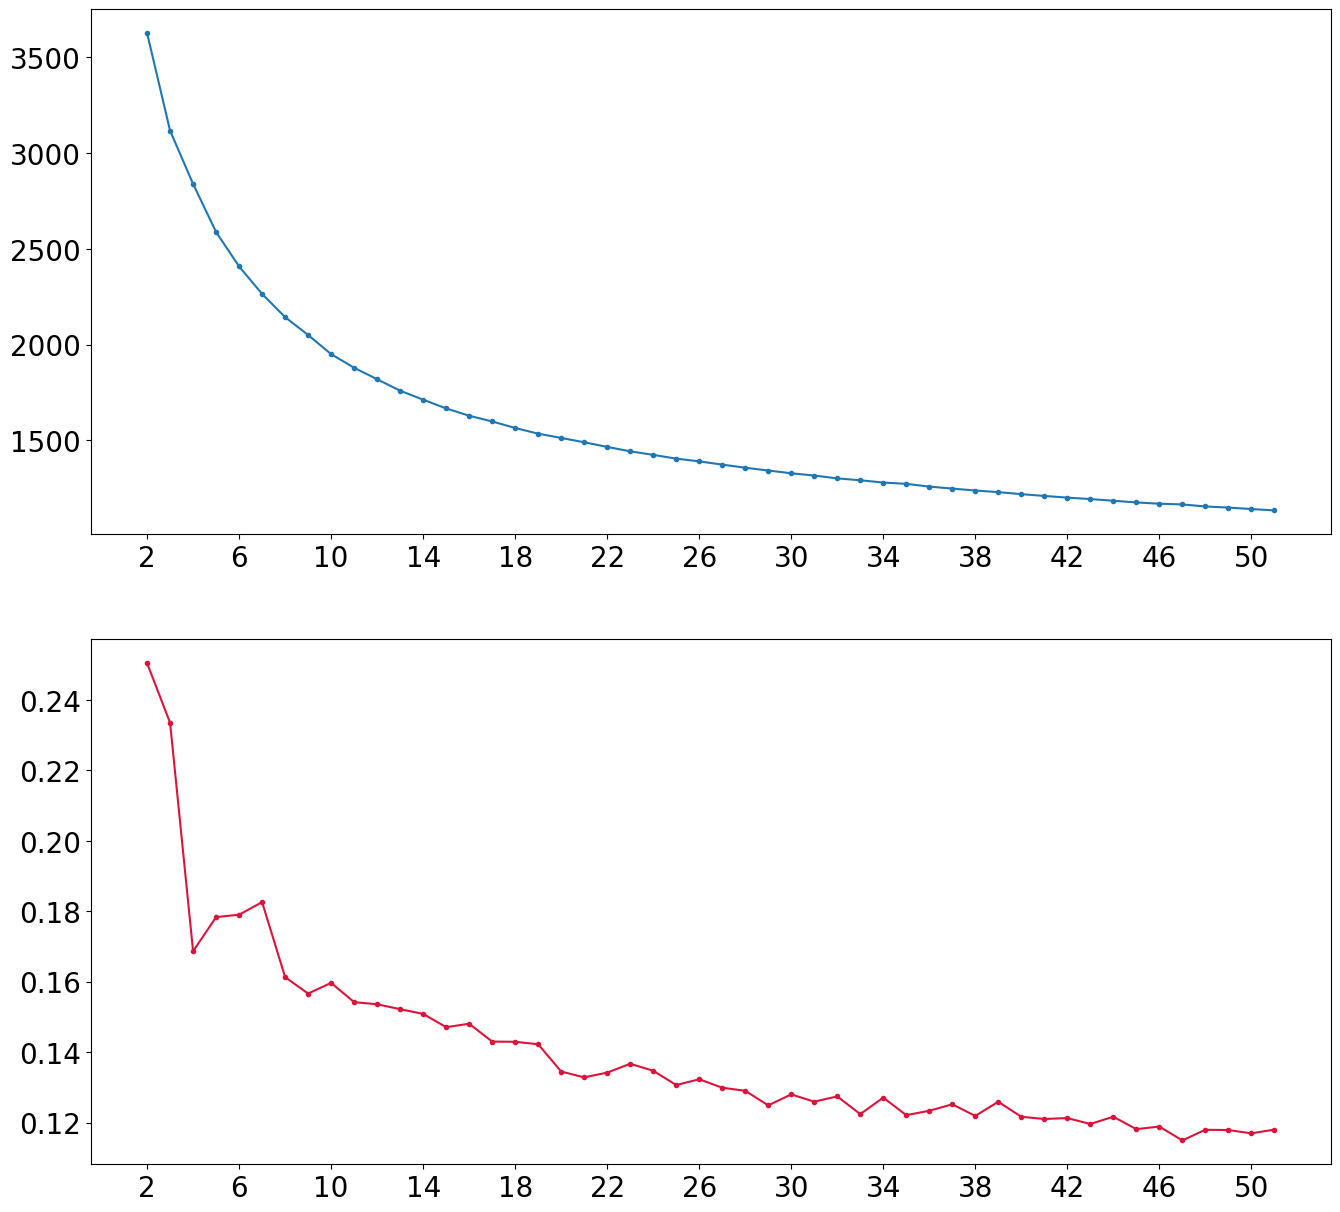

In [39]:
fig, (ax1, ax2) = plt.subplots(2, figsize=(16,15)) 

ax1.plot(np.arange(2,52), inertia, marker='.')
ax1.set_xticks(np.arange(2,52,4))

ax2.plot(np.arange(2,52), silhouette_scores, marker='.', color='crimson')
ax2.set_xticks(np.arange(2,52,4))
#ingrandisci etichette
plt.setp(ax1.get_xticklabels(), fontsize=20)
plt.setp(ax1.get_yticklabels(), fontsize=20)
plt.setp(ax2.get_xticklabels(), fontsize=20)
plt.setp(ax2.get_yticklabels(), fontsize=20)
#plt.savefig(fname='img/clustering_kmeans_SSE_and_Silhouette.png', dpi=300, bbox_inches='tight')

plt.show()

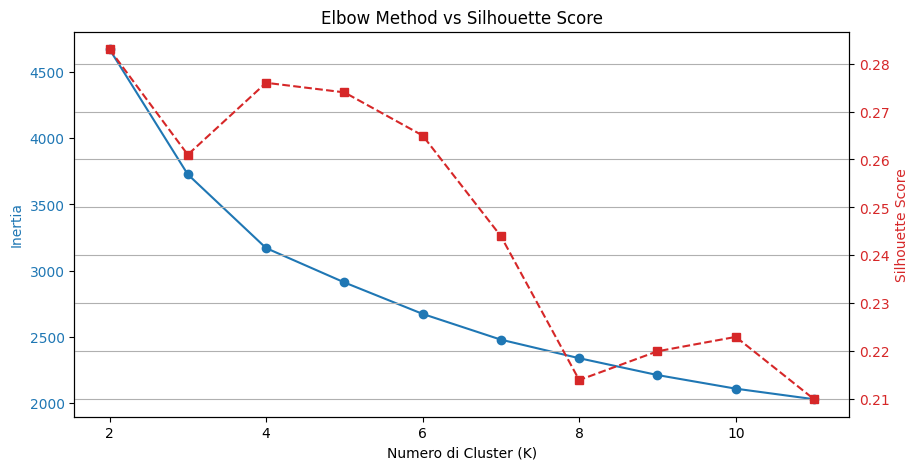

In [10]:

inertia = [4670.9, 3726.5, 3170.5, 2911.4, 2673.8, 2479.4, 2339.5, 2212.4, 2109.7, 2030.1]
silhouette = [0.283, 0.261, 0.276, 0.274, 0.265, 0.244, 0.214, 0.220, 0.223, 0.210]
k_values = range(2, 12)

fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot Inertia (Elbow)
ax1.set_xlabel('Numero di Cluster (K)')
ax1.set_ylabel('Inertia', color='tab:blue')
ax1.plot(k_values, inertia, 'o-', color='tab:blue', label='Inertia')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Plot Silhouette
ax2 = ax1.twinx()
ax2.set_ylabel('Silhouette Score', color='tab:red')
ax2.plot(k_values, silhouette, 's--', color='tab:red', label='Silhouette')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Elbow Method vs Silhouette Score')
plt.grid(True)
plt.show()

In [41]:
k = 6  # <--- Qui imposti il numero che hai deciso
kmeans = KMeans(n_clusters=k, n_init = 10, max_iter=1000, random_state=42) 
kmeans.fit(X) # Lo addestri sui dati

KMeans(max_iter=1000, n_clusters=6, n_init=10, random_state=42)

In [42]:
# Numero di punti per cluster e distribuzione percentuale
labels, counts = np.unique(kmeans.labels_, return_counts=True)
for l, c in zip(labels,counts):
    print('Cluster ', l, ': ', c, ' %: ' , (c/len(kmeans.labels_))*100)
print('Silhouette: ', silhouette_score(X, kmeans.labels_))
print('SSE: ', kmeans.inertia_)

Cluster  0 :  2672  %:  12.862850815963029
Cluster  1 :  5604  %:  26.97732633707216
Cluster  2 :  4963  %:  23.891590044769654
Cluster  3 :  2948  %:  14.191498579887355
Cluster  4 :  2269  %:  10.92283252298657
Cluster  5 :  2317  %:  11.153901699321233
Silhouette:  0.17904591494133162
SSE:  2408.296249299467


In [43]:
# 1. Aggiungiamo le etichette al dataset originale (df_train o df)
# Usiamo df_train se contiene i valori originali, oppure df
df_analysis = df_train.copy()  # Copia per non toccare l'originale
df_analysis['Cluster'] = kmeans.labels_

# 2. Raggruppiamo per cluster e calcoliamo la media delle feature
# Questo ci dirà, ad esempio, "Il Cluster 0 ha media peso 4.5 e durata 120min"
profile = df_analysis.groupby('Cluster').mean()

# 3. Ordinare per una colonna chiave (es. ComWeight o Rating) aiuta a leggere meglio
print(profile.sort_values(by='ComWeight'))

         YearPublished  ComWeight  MinPlayers  MaxPlayers  ComAgeRec  \
Cluster                                                                
1          2011.868665   1.485339    2.098680    5.912919   8.091720   
3          2010.285957   1.835242    2.063094    5.618046   8.478969   
4          1984.869987   1.855767    2.104011    5.429705   9.593213   
2          2014.150111   2.405141    1.985090    5.015112  10.957284   
5          2012.153647   3.072248    1.806215    4.496331  11.616746   
0          1997.082710   3.280435    1.908308    3.648952  13.858533   

         MfgAgeRec  NumOwned   NumWish  NumWeightVotes  ComMaxPlaytime  \
Cluster                                                                  
1         7.557994  5.148696  2.822765        1.624396        3.185553   
3         9.167232  7.517517  5.303160        3.884781        3.471405   
4         8.896430  5.496363  2.691173        2.339440        3.813379   
2        11.421721  5.613842  3.846971        1.98131

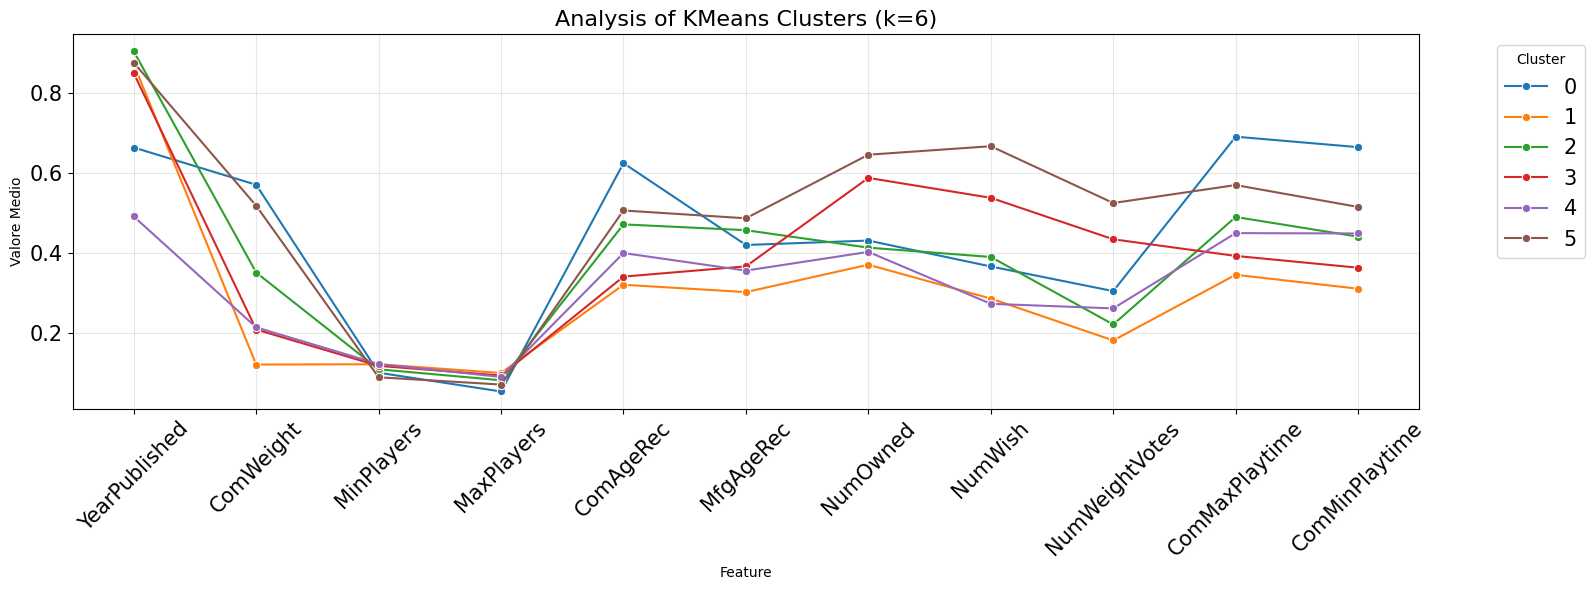

In [53]:
# 1. Creiamo un DataFrame con i centroidi
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=features)
centroids['Cluster'] = centroids.index

# 2. Trasformiamo i dati in formato "long" per il grafico (melt)
centroids_melted = pd.melt(centroids, 
                           id_vars=['Cluster'], 
                           var_name='Feature', 
                           value_name='Valore Medio')

# 3. Plot a linee (Snake Plot)
plt.figure(figsize=(16, 6))
sns.lineplot(data=centroids_melted, x='Feature', y='Valore Medio', hue='Cluster', palette='tab10', marker='o')

# Nota: uso k_scelto nel titolo per essere coerente
plt.title(f'Analysis of KMeans Clusters (k={k})', fontsize=16) 
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=15)
#ingrandisci valori x e y
plt.setp(plt.gca().get_xticklabels(), fontsize=15)
plt.setp(plt.gca().get_yticklabels(), fontsize=15)

plt.tight_layout()
plt.show()

In [15]:
# Esegui questo per vedere se abbiamo indovinato le etichette
for i in range(k):
    print(f"\n--- Esempi Cluster {i} ---")
    print(df.loc[kmeans.labels_ == i, 'Name'].sample(5, random_state=42).values)


--- Esempi Cluster 0 ---
['Jerusalem' "Lock 'n Load Tactical: Heroes of the Nam"
 'Ney vs. Wellington: The Battle of Quatre Bras'
 'Berserk: Trading Card Game' "1914: Glory's End / When Eagles Fight"]

--- Esempi Cluster 1 ---
['Pirate Plank' 'Top Face!' 'In Vino Morte' 'Dungeon Venture' 'Muses']

--- Esempi Cluster 2 ---
['Startup Fever' 'Allegiance: A Realm Divided' 'Ducks in Tow' 'ERA'
 'Biblios: Quill and Parchment']

--- Esempi Cluster 3 ---
['Star Wars PocketModel TCG' 'Aquaretto' 'Monopoly: Star Wars'
 'Star Wars: Angriff der Klonkrieger' 'Die Dolmengötter']

--- Esempi Cluster 4 ---
['Civil War' 'Sabotage' 'Octiles' "Oi! Dat's My Leg!" "WFF 'N PROOF"]

--- Esempi Cluster 5 ---
['Pandemic: Fall of Rome' 'Star Wars: Armada' 'Upon a Salty Ocean'
 'The Settlers of Zarahemla' 'Sail to India']


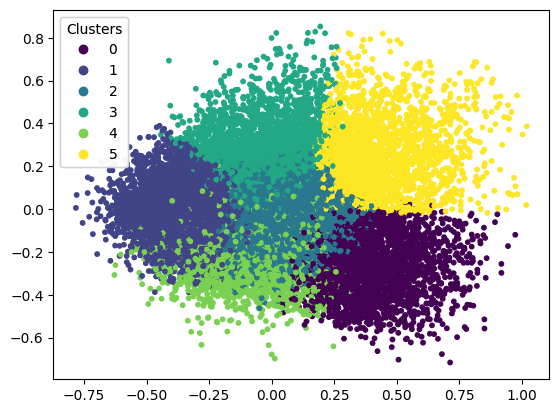

In [16]:
pca = PCA(n_components=2)  # Initialize a PCA model with 2 components
pca_data = pd.DataFrame(pca.fit_transform(X),columns=['PC1','PC2'])
pca_data['cluster'] = pd.Categorical(kmeans.labels_)

fig = plt.figure()
ax = fig.add_subplot()

scatter = ax.scatter(pca_data['PC1'],pca_data['PC2'],c=pca_data['cluster'], s=10)
ax.add_artist(ax.legend(*scatter.legend_elements(), loc="upper left", title="Clusters"))
# ax.view_init(elev=30., azim=155)  # Only for 3D plots


#plt.savefig(fname='../figures/kmeans_pca.png', dpi=300, bbox_inches='tight')
plt.show()


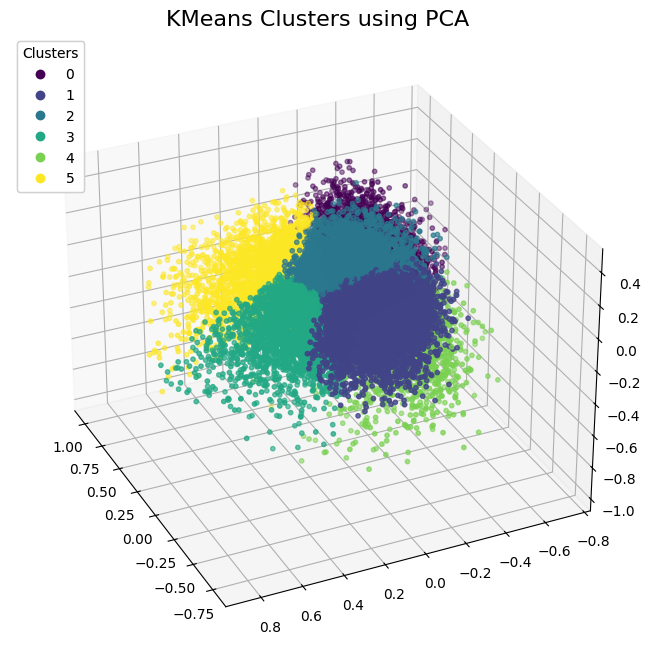

In [52]:
pca = PCA(n_components=3)  # Initialize a PCA model with 2 components
pca_data = pd.DataFrame(pca.fit_transform(X),columns=['PC1','PC2','PC3'])
pca_data['cluster'] = pd.Categorical(kmeans.labels_)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(projection='3d')

scatter = ax.scatter(pca_data['PC1'],pca_data['PC2'],pca_data['PC3'],c=pca_data['cluster'], s=10)
ax.add_artist(ax.legend(*scatter.legend_elements(), loc="upper left", title="Clusters"))
ax.view_init(elev=30., azim=155)
plt.title('KMeans Clusters using PCA', fontsize=16)
plt.setp(plt.gca().get_xticklabels(), fontsize=10)
plt.setp(plt.gca().get_yticklabels(), fontsize=10)

#plt.savefig(fname='../figures/kmeans_pca.png', dpi=300, bbox_inches='tight')
plt.show()

### Profilazione dei Cluster (Analisi Strutturale)

Dall'analisi dei centroidi emergono 6 profili distinti che coprono l'intero spettro del mercato ludico, ordinati qui per complessità crescente:

#### **1. Cluster 1: "Family & Party Games" (Accessibilità Totale)**

È il punto di ingresso nel mondo dei giochi, caratterizzato dalla massima accessibilità.

* **Dati Chiave:** Ha la complessità media più bassa (**1.49**) e il numero medio di giocatori più alto (**5.9**). L'età consigliata è minima (~8 anni).
* **Deduzione:** Sono giochi progettati per gruppi numerosi e famiglie. Regole immediate e bassa barriera d'ingresso (es. *Dixit, Uno, Party Games*).

#### **2. Cluster 3: "Gateway Games" (I Ponti)**

Rappresenta il passo successivo rispetto ai party games: giochi strutturati ma ancora accessibili.

* **Dati Chiave:** Complessità medio-bassa (**1.84**). Si distinguono per un buon livello di popolarità (`NumOwned` e `NumWish` elevati).
* **Deduzione:** Sono i titoli che trasformano un giocatore occasionale in un appassionato. Moderni, curati e molto diffusi (es. *Ticket to Ride, Carcassonne*).

#### **3. Cluster 4: "I Classici Vintage" (Old School)**

Un cluster definito quasi esclusivamente dalla sua collocazione temporale.

* **Dati Chiave:** La media dell'anno di pubblicazione crolla a **1985** (contro il 2010+ degli altri gruppi). Complessità medio-bassa (**1.86**).
* **Deduzione:** Raggruppa i giochi pubblicati prima del "Rinascimento" del gioco da tavolo moderno. Meccaniche spesso datate o tradizionali (es. *Monopoly, Risiko, vecchi wargame leggeri*).

#### **4. Cluster 2: "Modern Hobbyist" (Lo Standard Moderno)**

Rappresenta la "classe media" del mercato attuale, il cuore della collezione di un appassionato.

* **Dati Chiave:** Complessità media (**2.41**). Anno di pubblicazione molto recente (**~2014**). Durata e numero di giocatori standard.
* **Deduzione:** Giochi moderni che richiedono un certo impegno mentale senza essere estremi. È il segmento più prolifico negli ultimi anni (es. *Wingspan, 7 Wonders*).

#### **5. Cluster 5: "Strategy Blockbusters" (I Grandi Successi)**

Il gruppo dei "pesi massimi" che hanno sfondato nel mercato di massa.

* **Dati Chiave:** Combinano alta complessità (**3.07**) con la **massima popolarità assoluta** (il valore più alto di `NumOwned` e `NumWish`).
* **Deduzione:** Giochi complessi che sono diventati fenomeni di culto. Nonostante la difficoltà, sono posseduti da tantissime persone (es. *Terraforming Mars, Scythe*).

#### **6. Cluster 0: "Hardcore Heavy" (I Cinghiali)**

La nicchia per esperti puri, dove la complessità è il fine, non il mezzo.

* **Dati Chiave:** Massima complessità assoluta (**3.28**), massima durata (**Playtime** più alto) e numero minimo di giocatori (**3.6**). L'anno medio è **1997**, suggerendo titoli storici o molto consolidati.
* **Deduzione:** Wargames, giochi di civilizzazione profondi e titoli 18xx. Richiedono ore per essere giocati e settimane per essere padroneggiati.

---

### Tabella di Sintesi

| Cluster | Etichetta | Complessità | Caratteristica Dominante |
| --- | --- | --- | --- |
| **1** | **Family / Party** | Bassa (1.5) | Max Giocatori (5.9) |
| **3** | **Gateway** | Medio-Bassa (1.8) | Alta Diffusione |
| **4** | **Vintage** | Medio-Bassa (1.9) | Anno 1985 |
| **2** | **Modern Standard** | Media (2.4) | Recenti (2014) |
| **5** | **Strategy Hits** | Alta (3.1) | **Max Popolarità** |
| **0** | **Hardcore** | **Max (3.3)** | Max Durata / Min Giocatori |

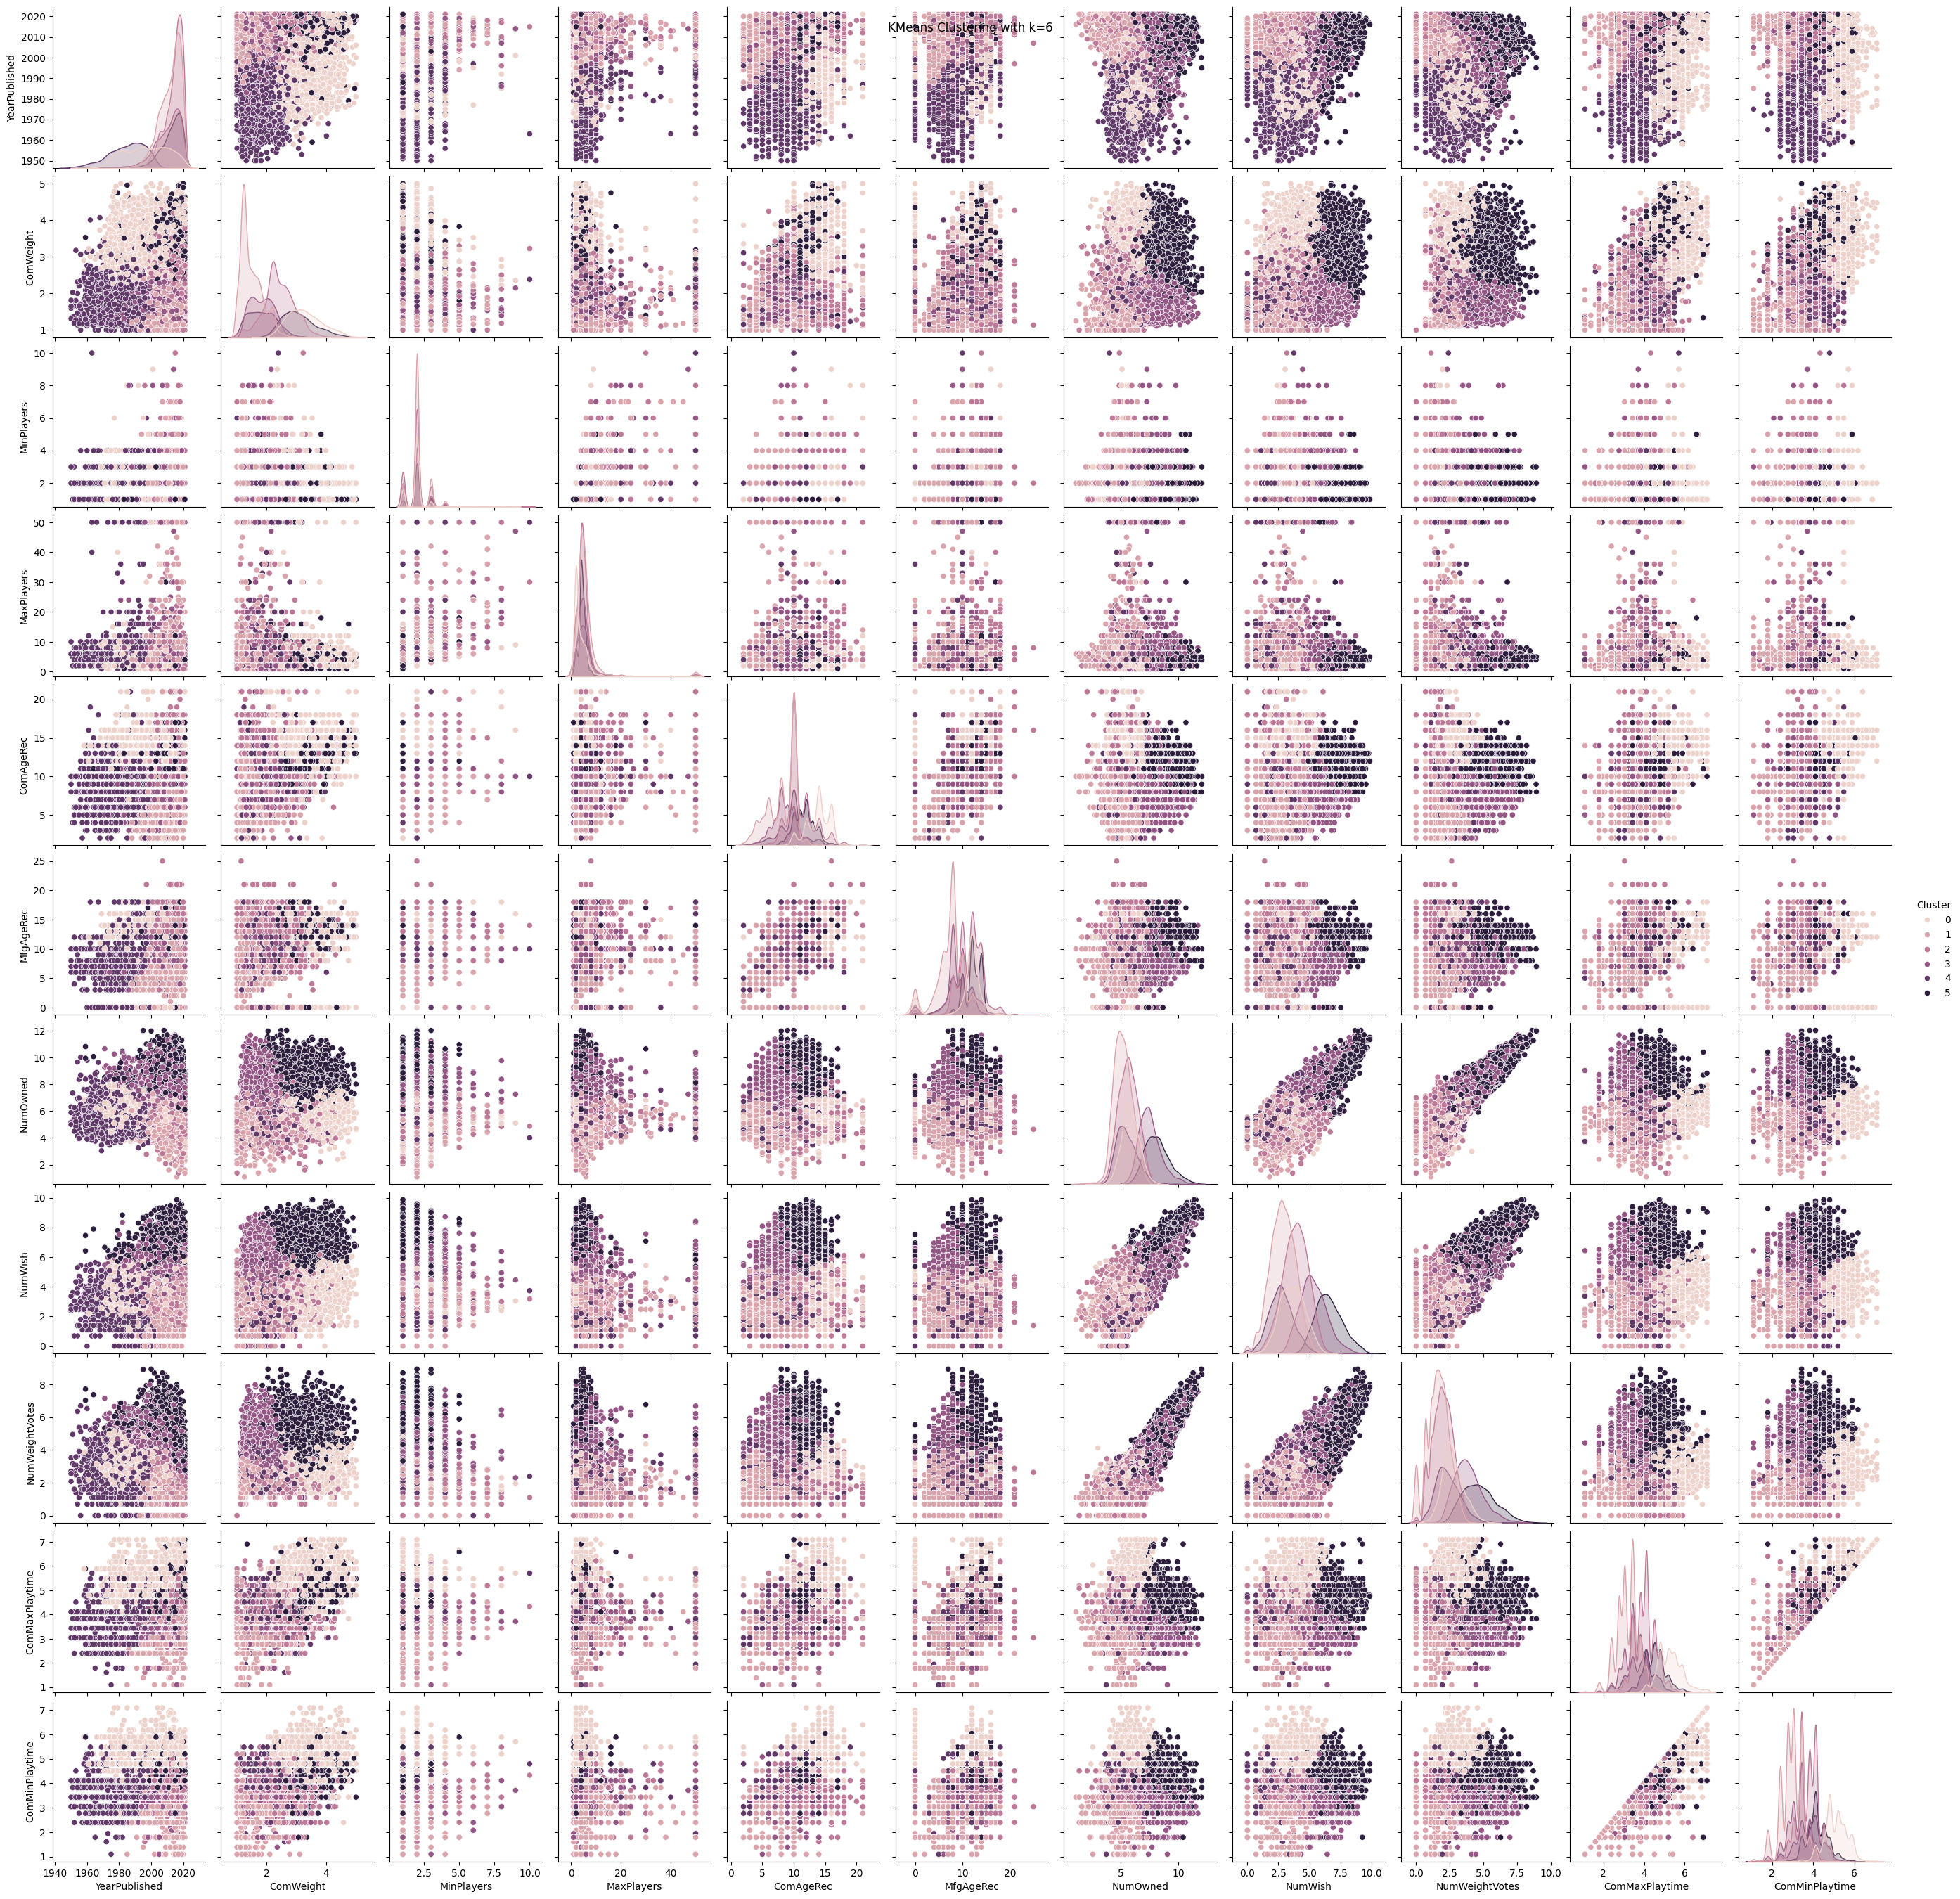

In [18]:
#k means with optimal k
df['Cluster'] = kmeans.labels_
df['Cluster'].value_counts()
sns.pairplot(df, hue='Cluster', vars=features)
plt.suptitle('KMeans Clustering with k={}'.format(k))
plt.show()

In [19]:

# 1. Selezioniamo le categorie
cat_columns = [col for col in df.columns if 'Cat:' in col]

# 2. CALCOLO FRAZIONATO (La magia avviene qui)
# Contiamo quante categorie ha ogni singolo gioco (es. Gioco A ha 2 categorie)
num_cats_per_game = df[cat_columns].sum(axis=1)

# Evitiamo divisioni per zero (se un gioco non ha categorie, lo ignoriamo o resta 0)
num_cats_per_game = num_cats_per_game.replace(0, 1) 

# Creiamo un dataframe "pesato"
# Se un gioco ha 2 categorie, i suoi "1" diventano "0.5"
df_weighted = df[cat_columns].div(num_cats_per_game, axis=0)

# Aggiungiamo il cluster
df_weighted['Cluster'] = df['Cluster']

# 3. Aggreghiamo per Cluster (Sommiamo i pesi)
weighted_counts = df_weighted.groupby('Cluster').sum()

# 4. Calcoliamo le Percentuali sulla base dei PESI
# REL % (Somma riga = 100%)
rel_perc = weighted_counts.div(weighted_counts.sum(axis=1), axis=0) * 100

# ABS % (Quota di mercato ponderata)
abs_perc = weighted_counts.div(df_weighted[cat_columns].sum(), axis=1) * 100

# 5. Costruiamo la Tabella Finale (Stile Paper)
# Prendiamo solo le top 10 categorie per pulizia
top_cats = df[cat_columns].sum().sort_values(ascending=False).head(10).index


frames = {}
for cat in top_cats:
    d = pd.DataFrame({
        'abs %': abs_perc[cat], 
        'rel %': rel_perc[cat]
    })
    frames[cat] = d

final_table = pd.concat(frames, axis=1)
final_table = final_table.round(2)
final_table


Cat:War        Cat:Strategy        Cat:Family        Cat:Thematic  \
          abs %  rel %        abs %  rel %      abs %  rel %        abs %   
Cluster                                                                     
0         65.62  86.69        10.15   8.27       0.44   0.34         8.55   
1          1.33   3.68         0.39   0.67      12.30  20.00         2.50   
2         15.66  37.48        13.98  20.65       7.22  10.17        14.59   
3          1.77   2.37        13.99  11.57      64.21  50.66        16.91   
4          7.26  21.98         2.50   4.68       7.99  14.23         7.12   
5          8.37  12.33        58.98  53.60       7.85   6.80        50.32   

               Cat:Abstract        Cat:Childrens        Cat:Party         \
         rel %        abs %  rel %         abs %  rel %     abs %  rel %   
Cluster                                                                    
0         3.42         1.00   0.38          0.00   0.00      0.49   0.11   
1         2.09        30.37  24.41         59.41  39.83     13.19   5.99   
2        10.58        14.82  10.31          0.86   0.50      9.31   3.66   
3         6.87        20.76   8.09         14.84   4.83     65.25  14.37   
4         6.53        29.95  26.36         24.88  18.27      8.82   4.39   
5        22.45         3.10   1.33          0.00   0.00      2.94   0.71   

        Cat:CGS        
          abs % rel %  
Cluster                
0          6.96  0.79  
1         14.11  3.34  
2         32.48  6.65  
3         10.72  1.23  
4         13.73  3.56  
5         22.01  2.77

<Figure size 1200x600 with 0 Axes>

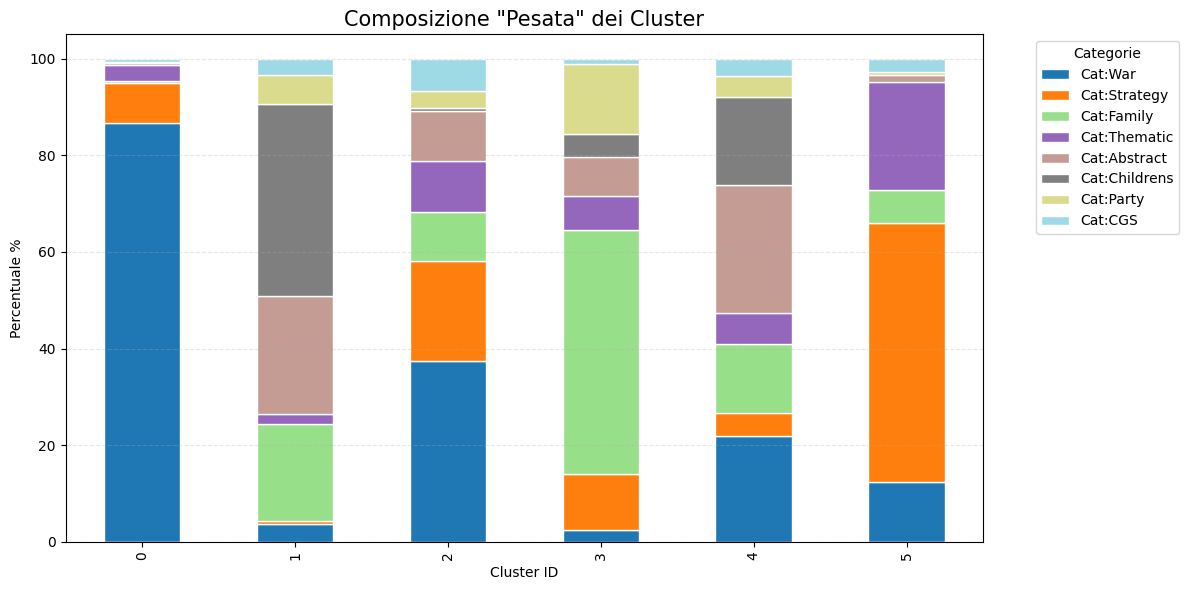

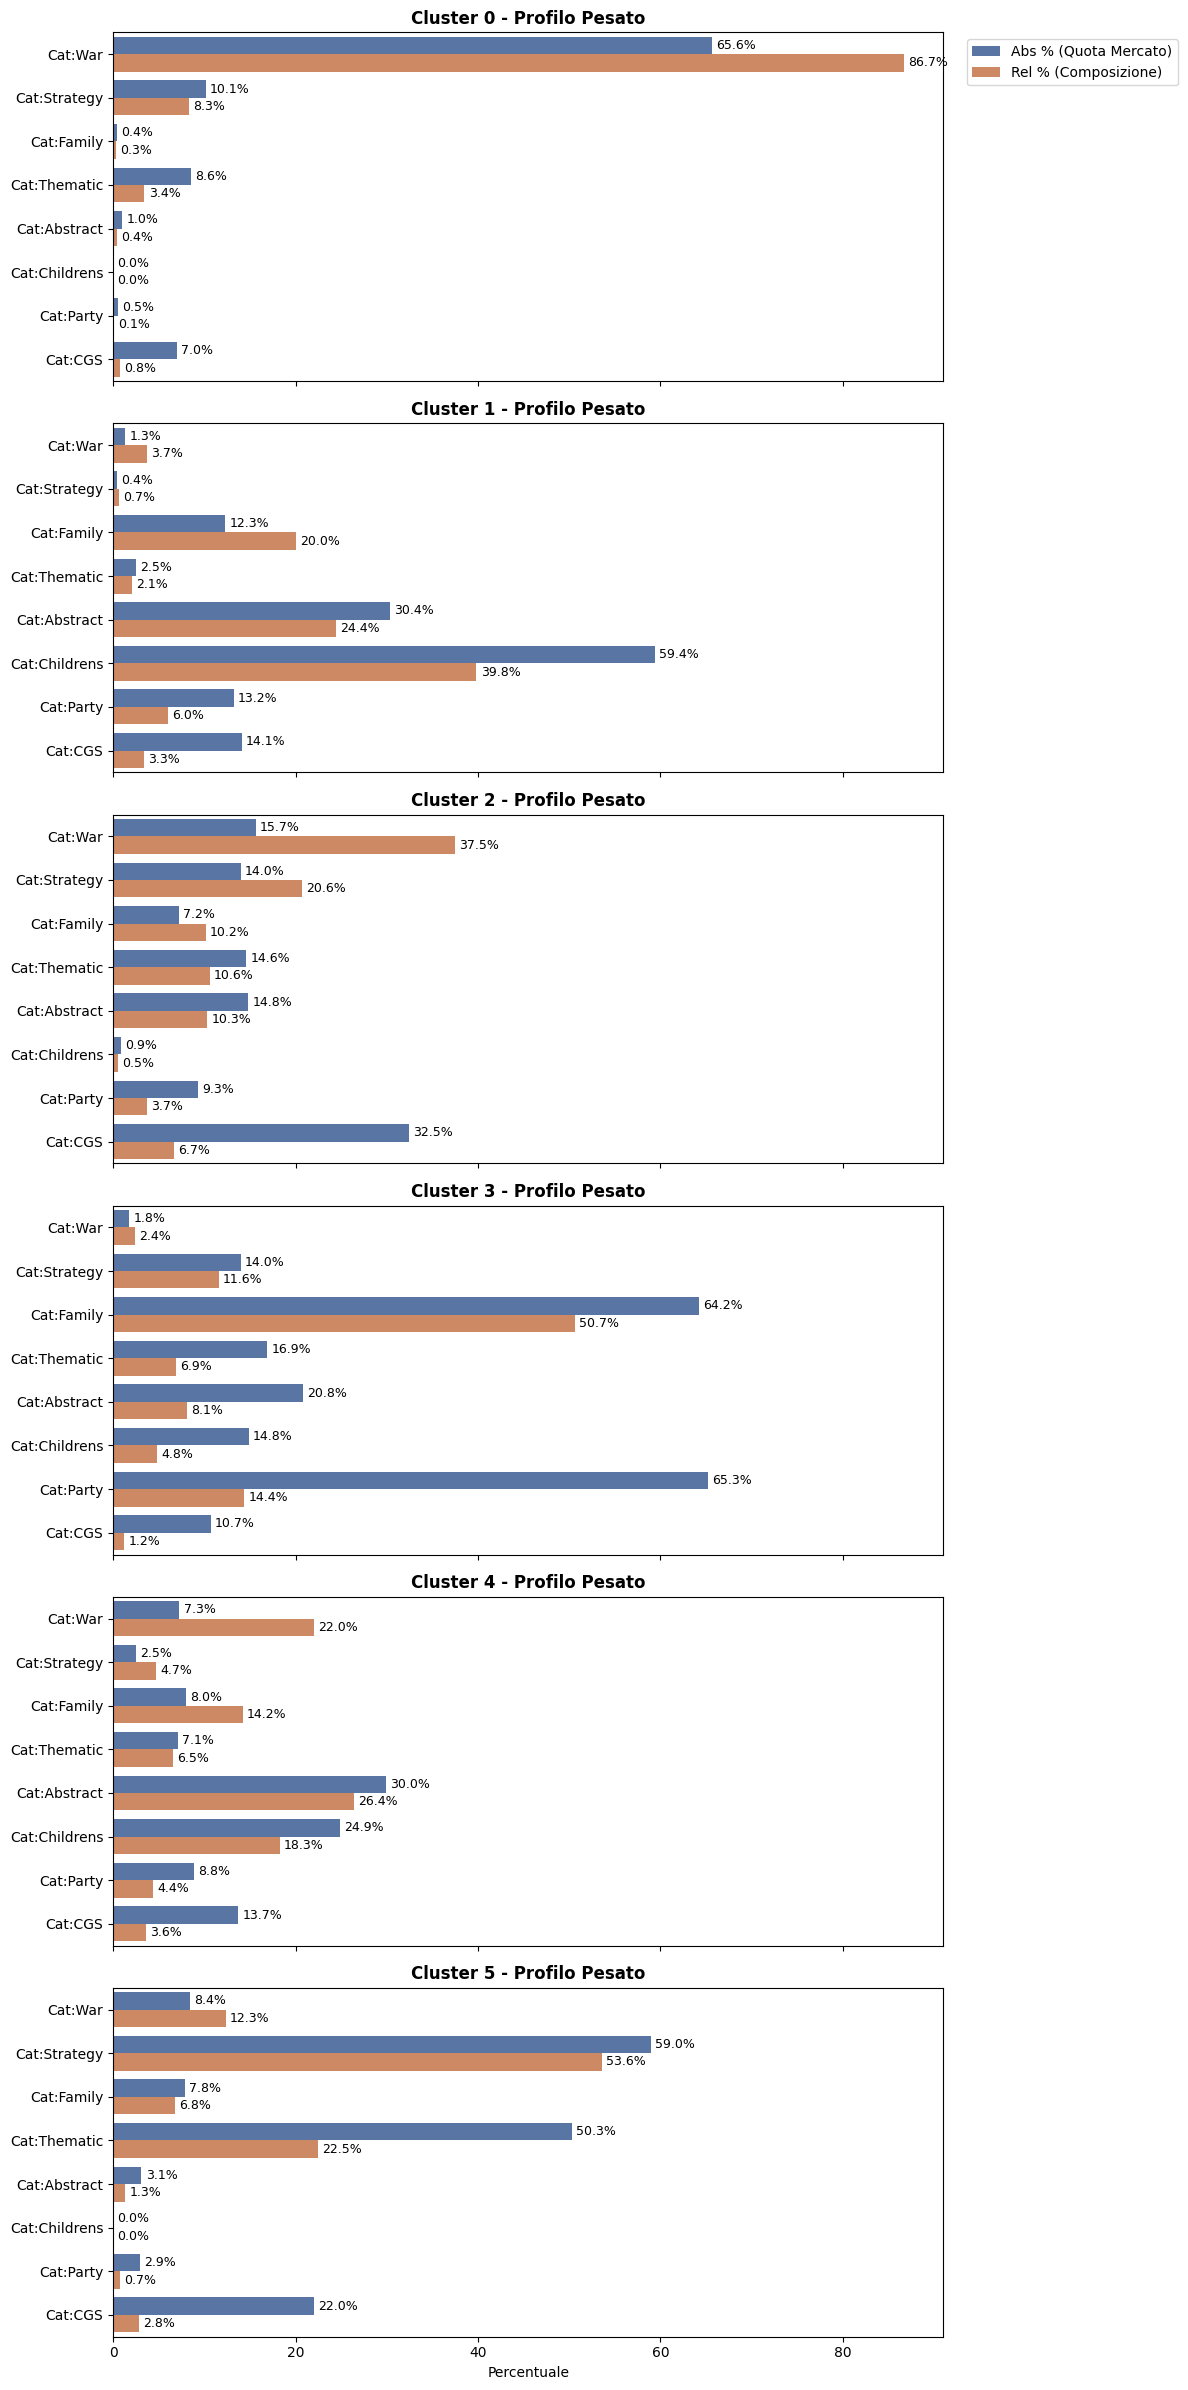

In [20]:

# --- 1. Ricalcoliamo i PESI (Parte Matematica) ---
cat_columns = [col for col in df.columns if 'Cat:' in col]

# Contiamo categorie per gioco e creiamo i pesi
num_cats_per_game = df[cat_columns].sum(axis=1).replace(0, 1)
df_weighted = df[cat_columns].div(num_cats_per_game, axis=0)
df_weighted['Cluster'] = df['Cluster']

# Aggreghiamo
weighted_counts = df_weighted.groupby('Cluster').sum()

# Calcoliamo le Percentuali Pesate
# Rel % (Composizione interna)
rel_perc = weighted_counts.div(weighted_counts.sum(axis=1), axis=0) * 100
# Abs % (Quota di mercato)
abs_perc = weighted_counts.div(df_weighted[cat_columns].sum(), axis=1) * 100

# Selezioniamo le Top 10 Categorie per i grafici
top_cats = df[cat_columns].sum().sort_values(ascending=False).head(10).index
rel_perc_top = rel_perc[top_cats]
abs_perc_top = abs_perc[top_cats]

# --- GRAFICO 1: Stacked Bar Chart (Composizione al 100%) ---
# Questo grafico mostra come è composto ogni cluster. La somma delle barre fa 100%.
plt.figure(figsize=(12, 6))
rel_perc_top.plot(kind='bar', stacked=True, colormap='tab20', figsize=(12, 6), edgecolor='white')

plt.title('Composizione "Pesata" dei Cluster', fontsize=15)
plt.ylabel('Percentuale %')
plt.xlabel('Cluster ID')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Categorie')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# --- GRAFICO 2: Small Multiples (Abs vs Rel) ---
# Questo è quello dettagliato per vedere anche la Quota di Mercato
n_clusters = len(weighted_counts)
fig, axes = plt.subplots(nrows=n_clusters, ncols=1, figsize=(12, 4 * n_clusters), sharex=True)
color_abs, color_rel = '#4c72b0', '#dd8452'

for i, ax in enumerate(axes):
    cluster_idx = weighted_counts.index[i]
    
    # Prepariamo i dati
    data_cluster = pd.DataFrame({
        'Categoria': top_cats,
        'Abs % (Quota Mercato)': abs_perc_top.loc[cluster_idx],
        'Rel % (Composizione)': rel_perc_top.loc[cluster_idx]
    }).melt(id_vars='Categoria', var_name='Tipo', value_name='Percentuale')
    
    sns.barplot(data=data_cluster, x='Percentuale', y='Categoria', hue='Tipo', ax=ax, palette=[color_abs, color_rel])
    
    ax.set_title(f'Cluster {cluster_idx} - Profilo Pesato', fontweight='bold')
    ax.set_ylabel('')
    ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontsize=9) # Abs labels
    ax.bar_label(ax.containers[1], fmt='%.1f%%', padding=3, fontsize=9) # Rel labels
    
    if i == 0: ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    else: ax.legend_.remove()

plt.tight_layout()
plt.show()